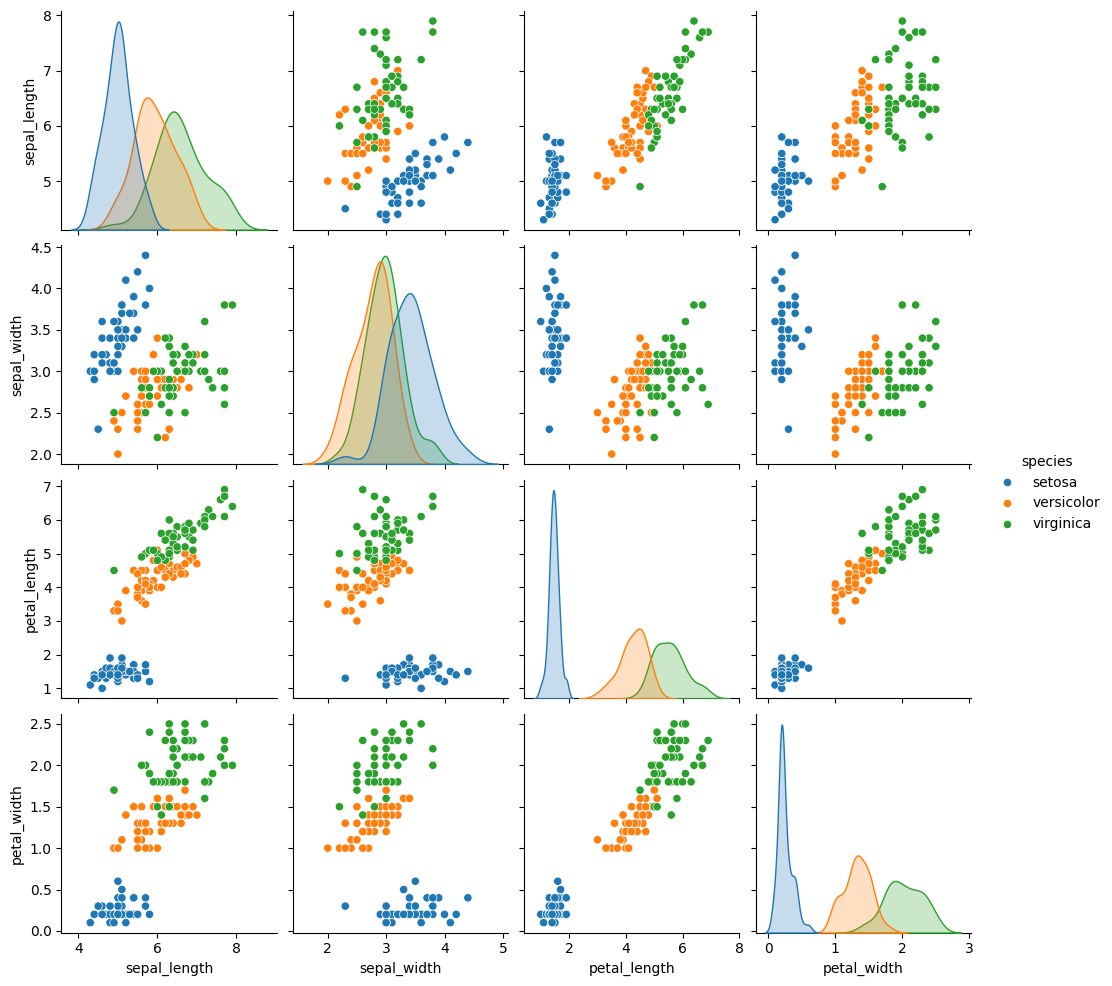

In [1]:
# Import necessary libraries
from sklearn.datasets import load_iris  # Load the built-in Iris dataset
from sklearn.model_selection import train_test_split  # Split data into training and testing sets
from sklearn.preprocessing import StandardScaler  # Standardize features
import matplotlib.pyplot as plt  # Create visualizations
import seaborn as sns  # Visualize data using statistical plots

# Step 1: Load the Iris dataset
data = load_iris()  # Load the dataset containing measurements of iris flowers
X, y = data.data, data.target  # X contains features; y contains target labels

# Step 2: Visualize the distribution and relationships between features
# Load the Iris dataset using Seaborn and create pairwise scatterplots
# The hue='species' parameter colors the data points according to flower species

sns.pairplot(sns.load_dataset('iris'), hue='species')
plt.show()  # Display the pairplot

# Step 3: Split the dataset into training and testing sets
# test_size=0.2 reserves 20% of the data for testing and 80% for training
# random_state=42 ensures reproducibility of the split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Step 4: Standardize the features (optional but useful for many ML algorithms)
# StandardScaler transforms features to have a mean of approximately 0
# and a standard deviation of approximately 1

scaler = StandardScaler()

# Fit the scaler on the training data and transform the training features
X_train = scaler.fit_transform(X_train)

# Use the same scaler to transform the test features
# This prevents information from the test set leaking into the training process

X_test = scaler.transform(X_test)

Random Forest Model Training and Decision Tree Visualization

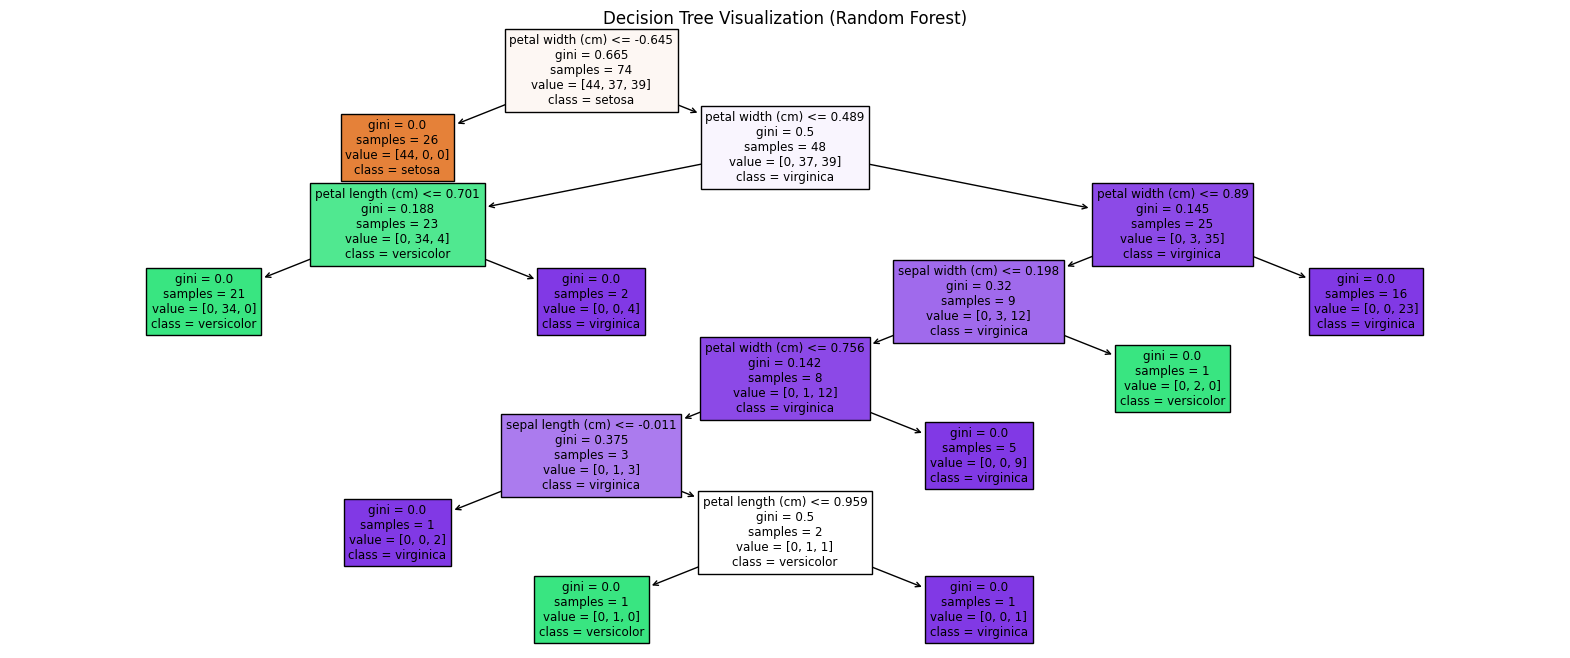

In [2]:
# Import the function to visualize decision trees
from sklearn.tree import plot_tree

# Import the Random Forest classification algorithm
from sklearn.ensemble import RandomForestClassifier

# Step 1: Initialize the Random Forest model
# n_estimators=100 means the model will contain 100 decision trees
# random_state=42 ensures reproducible results

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Step 2: Train the Random Forest model
# The model learns patterns from the training features (X_train) and their corresponding target labels (y_train)

rf_model.fit(X_train, y_train)

# Step 3: Create a figure for visualizing one decision tree

plt.figure(figsize=(20, 8))

# Step 4: Plot the first decision tree from the Random Forest
# rf_model.estimators_[0] selects the first tree among the 100 trees
# feature_names displays the names of the input features
# class_names displays the names of the Iris flower species
# filled=True colors the nodes according to their predicted classes

plot_tree(
    rf_model.estimators_[0],
    feature_names=data.feature_names,
    class_names=data.target_names,
    filled=True
)
plt.title("Decision Tree Visualization (Random Forest)")
plt.show()


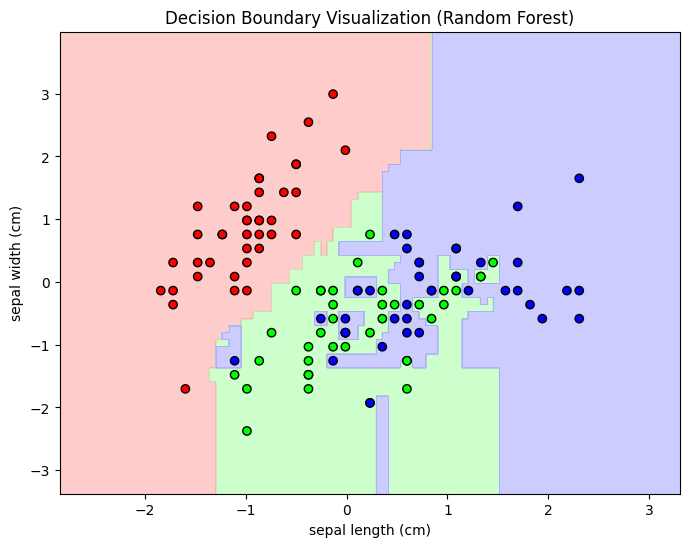

In [3]:
from matplotlib.colors import ListedColormap  # Define custom colors for visualization
import numpy as np  
from sklearn.ensemble import RandomForestClassifier  

# Step 1: Select two features for visualization
# A decision boundary can be plotted in 2D using two features
# Here, we select the first two features from the training and test datasets

X_train_2d = X_train[:, :2]
X_test_2d = X_test[:, :2]

# Step 2: Train a new Random Forest model using only two features
# n_estimators=100 creates 100 decision trees
# random_state=42 ensures reproducibility

rf_model_2d = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model using the selected features and training labels
rf_model_2d.fit(X_train_2d, y_train)

# Step 3: Define the plotting boundaries
# Find the minimum and maximum values of both features
# Add a margin of 1 unit around the data for better visualization

x_min, x_max = X_train_2d[:, 0].min() - 1, X_train_2d[:, 0].max() + 1
y_min, y_max = X_train_2d[:, 1].min() - 1, X_train_2d[:, 1].max() + 1

# Step 4: Create a mesh grid
# np.arange() generates evenly spaced values at intervals of 0.01
# np.meshgrid() creates coordinate pairs covering the plotting area

xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.01),
    np.arange(y_min, y_max, 0.01)
)

# Step 5: Predict the class for every point in the mesh grid
# Flatten the grid coordinates and combine them into two-feature input rows
Z = rf_model_2d.predict(np.c_[xx.ravel(), yy.ravel()])

# Reshape the predictions to match the dimensions of the mesh grid
Z = Z.reshape(xx.shape)

# Step 6: Visualize the decision boundaries
# Create a figure with a width of 8 inches and height of 6 inches
plt.figure(figsize=(8, 6))

# Fill the background with colors representing the predicted classes
# alpha=0.6 controls the transparency of the background
plt.contourf(
    xx, yy, Z,
    alpha=0.6,
    cmap=ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'])
)

# Plot the actual training data points
# c=y_train colors each point according to its actual species
# edgecolor='k' adds black borders around the points
plt.scatter(
    X_train_2d[:, 0],
    X_train_2d[:, 1],
    c=y_train,
    edgecolor='k',
    cmap=ListedColormap(['#FF0000', '#00FF00', '#0000FF'])
)

# Step 7: Add axis labels and a title
plt.xlabel(data.feature_names[0])  # Label the x-axis with the first feature
plt.ylabel(data.feature_names[1])  # Label the y-axis with the second feature
plt.title("Decision Boundary Visualization (Random Forest)")

# Display the final visualization
plt.show()

Random Forest Classification Using Bagging – Confusion Matrix Visualization

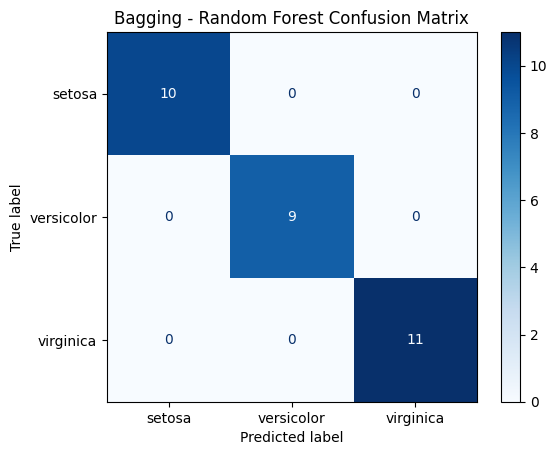

In [4]:
# Random Forest Classification Using Bagging Technique

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Step 1: Initialize the Random Forest model
# n_estimators=100 creates 100 decision trees
# random_state=42 ensures reproducible results

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Step 3: Predict the target classes for the test dataset
rf_predictions = rf_model.predict(X_test)

# Step 4: Calculate the confusion matrix
# Compare actual labels (y_test) with predicted labels (rf_predictions)
cm = confusion_matrix(y_test, rf_predictions)

# Step 5: Visualize the confusion matrix
# Display the Iris species names as labels
# cmap='Blues' applies a blue color scheme

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=data.target_names
).plot(cmap='Blues')
plt.title('Bagging - Random Forest Confusion Matrix')
plt.show()


 Feature Importance Analysis Using Random Forest

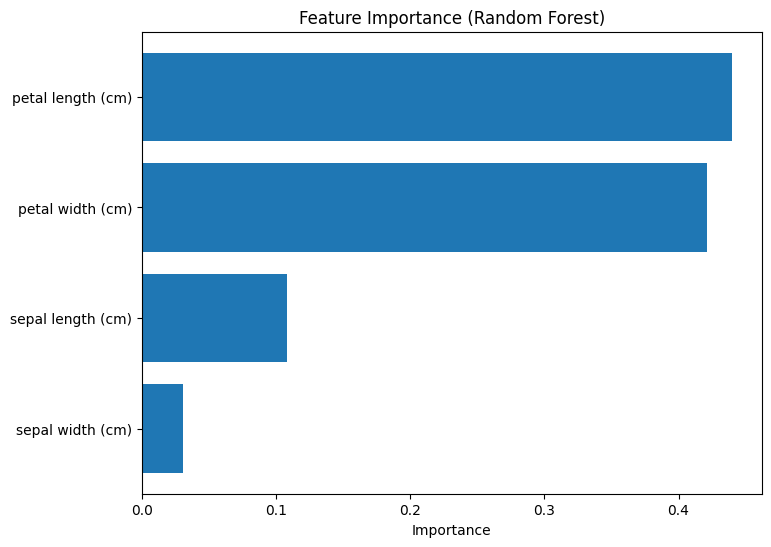

In [5]:
import numpy as np

# Step 1: Extract feature importance scores from the trained Random Forest model
# Higher scores indicate that a feature contributed more to the model's predictions

feature_importances = rf_model.feature_importances_

# Get the names of the input features from the Iris dataset
features = data.feature_names

# Step 2: Sort the features by importance in ascending order
indices = np.argsort(feature_importances)

plt.figure(figsize=(8, 6))
plt.title("Feature Importance (Random Forest)")
plt.barh(
    range(len(features)),
    feature_importances[indices],
    align="center"
)

# Display the corresponding feature names on the y-axis
plt.yticks(range(len(features)), np.array(features)[indices])
plt.xlabel("Importance")
plt.show()


Cumulative Feature Importance Analysis Using Random Forest

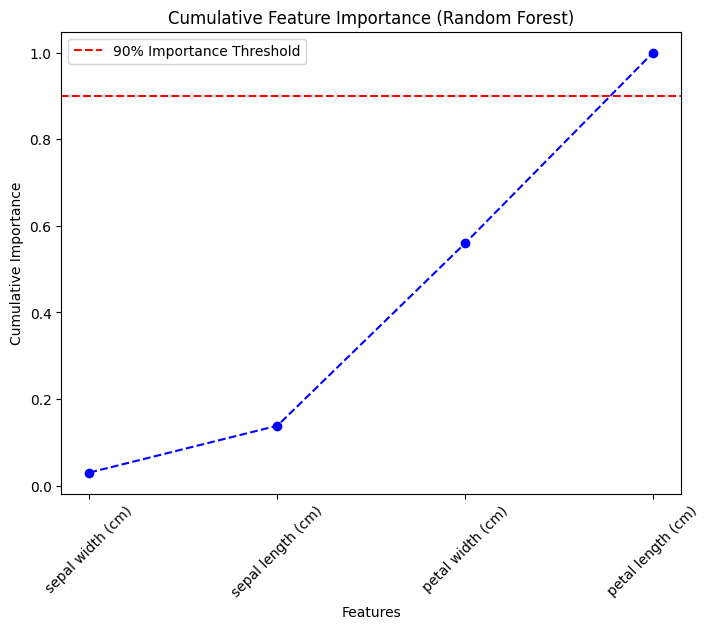

In [6]:
# Step 1: Calculate cumulative feature importance
# np.cumsum() calculates the running total of feature importance scores
# The features are arranged according to their importance using indices
cumulative_importance = np.cumsum(feature_importances[indices])

# Step 2: Create a figure for visualization
plt.figure(figsize=(8, 6))

# Step 3: Plot cumulative feature importance
# marker='o' displays a circle at each data point
# linestyle='--' connects the points using a dashed line

plt.plot(
    range(len(features)),
    cumulative_importance,
    marker='o',
    linestyle='--',
    color='b'
)

# Step 4: Display feature names on the x-axis
# The names follow the ascending order of feature importance

plt.xticks(
    range(len(features)),
    np.array(features)[indices],
    rotation=45
)
plt.xlabel("Features")
plt.ylabel("Cumulative Importance")
plt.title("Cumulative Feature Importance (Random Forest)")

# Step 6: Add a horizontal line at the 90% importance threshold
# This helps identify how many features collectively account for 90% of the total feature importance.

plt.axhline(
    y=0.9,
    color='r',
    linestyle='--',
    label='90% Importance Threshold'
)
plt.legend()
plt.show()


Gradient Boosting Classification Using Boosting Technique

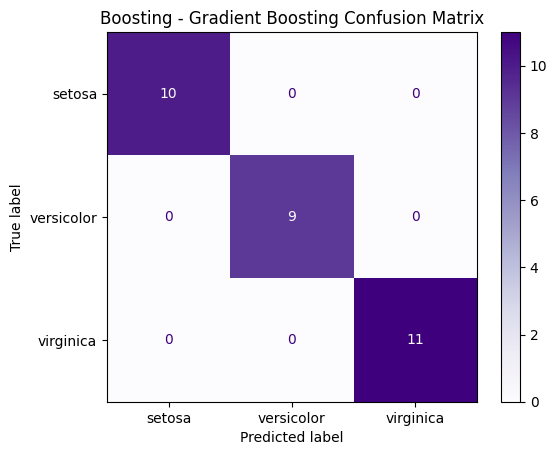

In [7]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Step 1: Initialize the Gradient Boosting model
# n_estimators=100 specifies the number of boosting stages
# random_state=42 ensures reproducible results

gb_model = GradientBoostingClassifier(
    n_estimators=100,
    random_state=42
)

# Step 2: Train the Gradient Boosting model. The model learns patterns from the training features and target labels
gb_model.fit(X_train, y_train)

# Step 3: Predict the classes for the test dataset
gb_predictions = gb_model.predict(X_test)

# Step 4: Calculate the confusion matrix
# Compare actual test labels with the predicted labels
cm = confusion_matrix(y_test, gb_predictions)

# Step 5: Visualize the confusion matrix
# Display the names of the three Iris flower species
# cmap='Purples' applies a purple color scheme
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=data.target_names
).plot(cmap='Purples')

# Step 6: Add a title and display the visualization
plt.title('Boosting - Gradient Boosting Confusion Matrix')
plt.show()


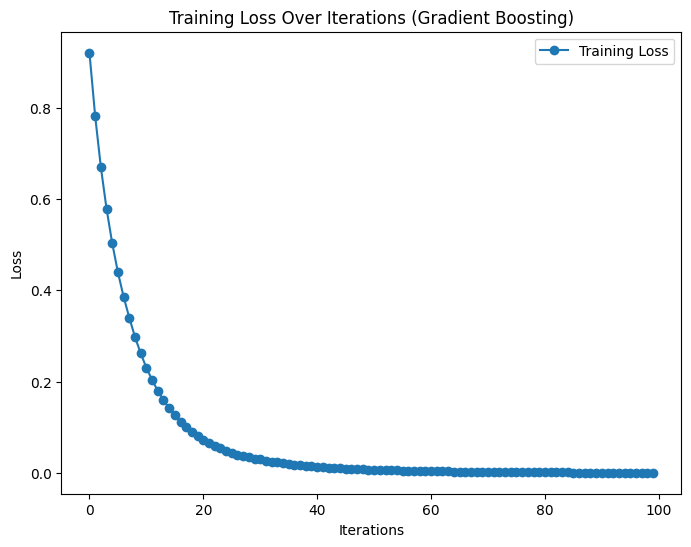

In [8]:
plt.figure(figsize=(8, 6))

# Step 2: Plot the training loss recorded at each boosting stage
# gb_model.train_score_ stores the training loss for each iteration

plt.plot(
    gb_model.train_score_,
    marker='o',
    label='Training Loss'
)
plt.title("Training Loss Over Iterations (Gradient Boosting)")
plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.legend()
plt.show()

# Interpretation: The plot shows how the training loss changes as the Gradient Boosting model adds successive trees. A decreasing loss generally indicates that the model is fitting the training data better.
# Note: Training loss alone cannot establish whether the model generalizes well. Evaluate performance on the test set or use validation data to check for overfitting.


Learning Curve Analysis Using Gradient Boosting

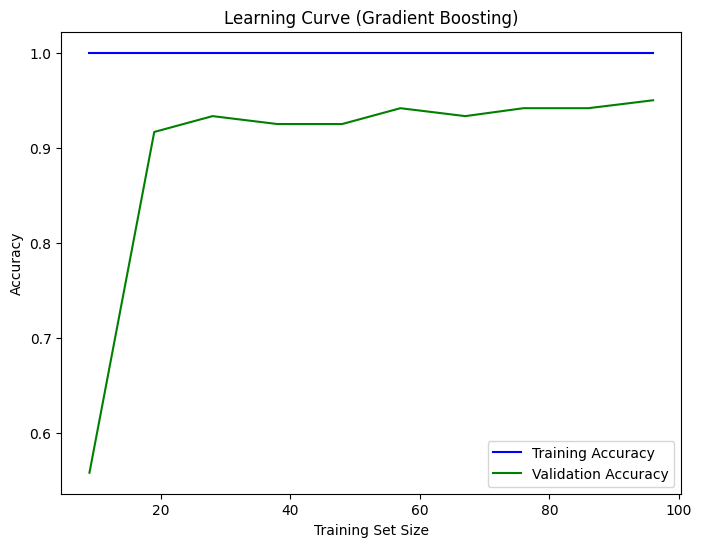

In [9]:
from sklearn.model_selection import learning_curve

# Step 1: Calculate training and validation scores for different training set sizes
# cv=5 performs 5-fold cross-validation
# train_sizes defines 10 training set sizes between 10% and 100%
# scoring='accuracy' evaluates model performance using classification accuracy

train_sizes, train_scores, test_scores = learning_curve(
    gb_model,
    X_train,
    y_train,
    cv=5,
    train_sizes=np.linspace(0.1, 1.0, 10),
    scoring='accuracy'
)

# Step 2: Calculate the average training accuracy across the 5 folds
# axis=1 calculates the mean for each training set size

train_mean = np.mean(train_scores, axis=1)

# Calculate the average validation accuracy across the 5 folds
test_mean = np.mean(test_scores, axis=1)
plt.figure(figsize=(8, 6))

# Step 4: Plot the training accuracy
plt.plot(
    train_sizes,
    train_mean,
    label='Training Accuracy',
    color='b'
)

# Plot the validation accuracy
plt.plot(
    train_sizes,
    test_mean,
    label='Validation Accuracy',
    color='g'
)

# Step 5: Label the axes
plt.xlabel("Training Set Size")
plt.ylabel("Accuracy")
plt.title("Learning Curve (Gradient Boosting)")
plt.legend()
plt.show()


AdaBoost Classification Using Boosting Technique – Confusion Matrix Visualization

c:\Users\rroha\Python 3.11 Raj\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:519: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(


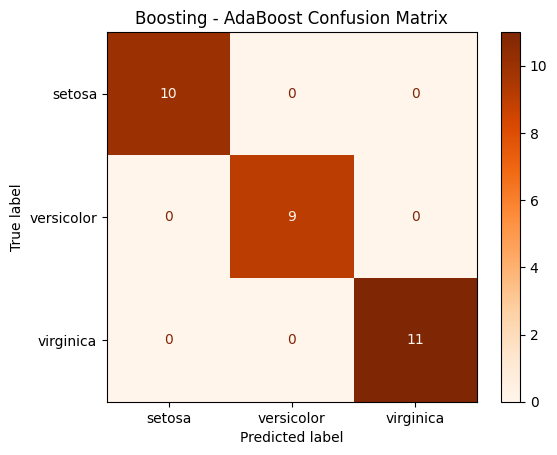

In [10]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Step 1: Initialize the AdaBoost model
# n_estimators=100 specifies the maximum number of boosting estimators
# random_state=42 ensures reproducible results
ada_model = AdaBoostClassifier(
    n_estimators=100,
    random_state=42
)

# Step 2: Train the AdaBoost model using the training dataset
ada_model.fit(X_train, y_train)

# Step 3: Predict the Iris species for the test dataset
ada_predictions = ada_model.predict(X_test)

# Step 4: Calculate the confusion matrix
# Compare actual labels with the predicted labels
cm = confusion_matrix(y_test, ada_predictions)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=data.target_names
).plot(cmap='Oranges')
plt.title('Boosting - AdaBoost Confusion Matrix')
plt.show()


In [11]:
# from sklearn.ensemble import StackingClassifier
# from sklearn.linear_model import LogisticRegression
# from sklearn.tree import DecisionTreeClassifier
# from sklearn.svm import SVC

# # Step 1: Define the base models for stacking
# # Decision Tree learns decision rules from the training data
# # SVC identifies decision boundaries between different classes
# # probability=True enables probability estimates for SVC

# estimators = [
#     ('dt', DecisionTreeClassifier()),
#     ('svc', SVC(probability=True))
# ]

# # Step 2: Define the meta-model
# # Logistic Regression combines the predictions of the base models
# final_estimator = LogisticRegression()

# # Step 3: Initialize the Stacking Classifier
# # The base models generate predictions that are used to train the meta-model
# stack_model = StackingClassifier(
#     estimators=estimators,
#     final_estimator=final_estimator
# )

# # Step 4: Train the stacking model
# stack_model.fit(X_train, y_train)

# # Step 5: Predict the classes for the test dataset
# stack_predictions = stack_model.predict(X_test)

# # Step 6: Calculate the confusion matrix
# # Compare actual test labels with predicted labels
# cm = confusion_matrix(y_test, stack_predictions)

# # Step 7: Visualize the confusion matrix
# # Display the names of the Iris flower species
# # cmap='Greens' applies a green color scheme
# ConfusionMatrixDisplay(
#     confusion_matrix=cm,
#     display_labels=data.target_names
# ).plot(cmap='Greens')

# # Step 8: Add a title and display the visualization
# plt.title('Stacking Confusion Matrix')
# plt.show()

In [12]:
# # Visualize the predictions from each base model to show their individual strengths and weaknesses.
# # Comparing between Decision Tree and SVC
# base_model_predictions = [stack_model.named_estimators_['dt'].predict(X_test),
#                           stack_model.named_estimators_['svc'].predict(X_test)]

# plt.figure(figsize=(10, 6))
# for i, preds in enumerate(base_model_predictions):
#     plt.subplot(1, 2, i + 1)
#     sns.scatterplot(x=X_test[:, 0], y=X_test[:, 1], hue=preds, palette='coolwarm')
#     plt.title(f"Predictions from Base Model {i + 1}")
#     plt.xlabel(data.feature_names[0])
#     plt.ylabel(data.feature_names[1])
# plt.tight_layout()
# plt.show()


Hyperparameter Tuning for Random Forest Using GridSearchCV

In [13]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

# Step 1: Define the hyperparameters to be tested
# n_estimators specifies the number of decision trees
# max_depth controls the maximum depth of each tree
param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [None, 10, 20]
}

# Step 2: Initialize GridSearchCV
# GridSearchCV tests all combinations of the specified hyperparameters
# cv=5 performs 5-fold cross-validation
grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

# Step 3: Train and evaluate the different parameter combinations
grid_search.fit(X_train, y_train)

# Step 4: Display the best hyperparameters
print(f"Best parameters for Random Forest: {grid_search.best_params_}")

# Step 5: Display the best cross-validation accuracy
print(f"Best cross-validation accuracy: {grid_search.best_score_:.4f}")

# Step 6: Retrieve the best-performing model
best_rf_model = grid_search.best_estimator_


Best parameters for Random Forest: {'max_depth': None, 'n_estimators': 150}
Best cross-validation accuracy: 0.9583


Model Evaluation and Accuracy Comparison of Ensemble Learning Techniques

In [14]:
from sklearn.metrics import accuracy_score

# Step 1: Calculate the accuracy of each trained model
# Accuracy measures the proportion of correctly classified test samples

rf_accuracy = accuracy_score(y_test, rf_predictions)
gb_accuracy = accuracy_score(y_test, gb_predictions)
ada_accuracy = accuracy_score(y_test, ada_predictions)

# Step 2: Display the accuracy of each model
print(f"Random Forest Accuracy: {rf_accuracy:.2f}")
print(f"Gradient Boosting Accuracy: {gb_accuracy:.2f}")
print(f"AdaBoost Accuracy: {ada_accuracy:.2f}")


Random Forest Accuracy: 1.00
Gradient Boosting Accuracy: 1.00
AdaBoost Accuracy: 1.00


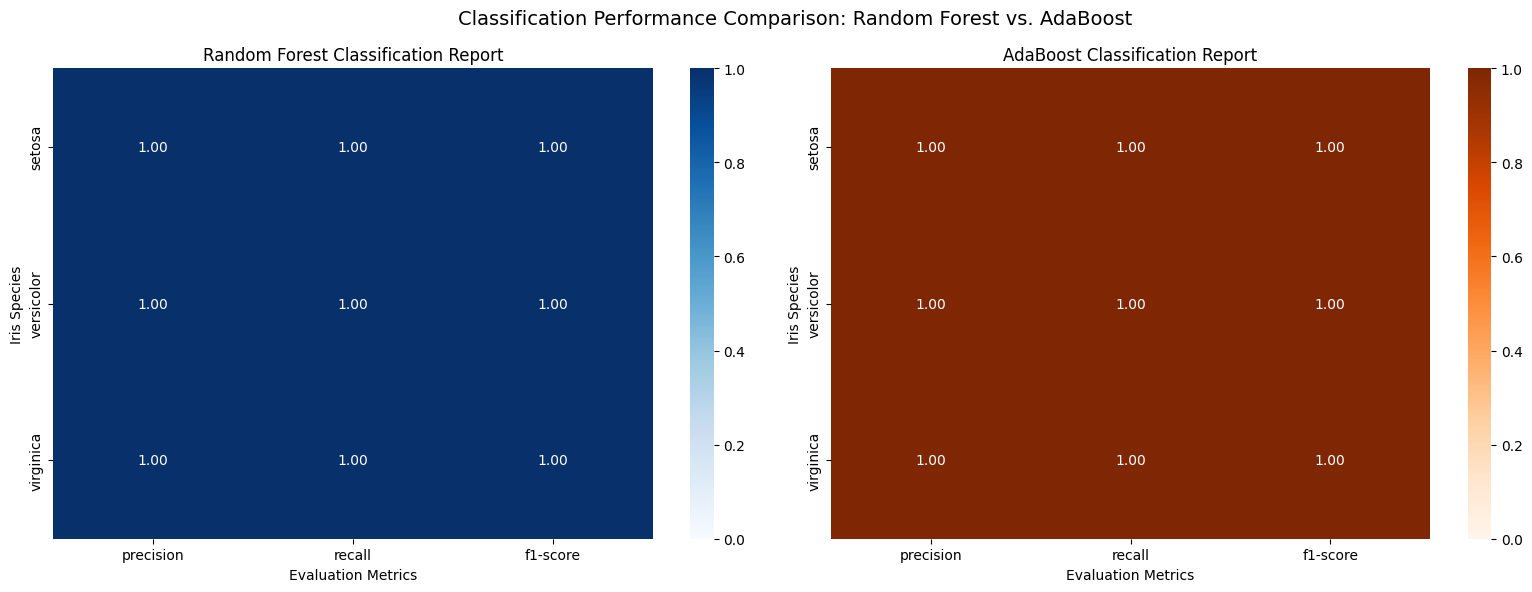

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report

# Step 1: Generate classification reports for both models
rf_report = classification_report(
    y_test, rf_predictions,
    target_names=data.target_names,
    output_dict=True
)

ada_report = classification_report(
    y_test, ada_predictions,
    target_names=data.target_names,
    output_dict=True
)

# Step 2: Convert classification reports into DataFrames
rf_df = pd.DataFrame(rf_report).transpose()
ada_df = pd.DataFrame(ada_report).transpose()

# Step 3: Select precision, recall, and F1-score for each Iris species
metrics = ['precision', 'recall', 'f1-score']

rf_species = rf_df.loc[data.target_names, metrics]
ada_species = ada_df.loc[data.target_names, metrics]

# Step 4: Create visualizations
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Random Forest classification performance
sns.heatmap(
    rf_species,
    annot=True,
    fmt='.2f',
    cmap='Blues',
    vmin=0,
    vmax=1,
    ax=axes[0]
)
axes[0].set_title('Random Forest Classification Report')
axes[0].set_xlabel('Evaluation Metrics')
axes[0].set_ylabel('Iris Species')

# AdaBoost classification performance
sns.heatmap(
    ada_species,
    annot=True,
    fmt='.2f',
    cmap='Oranges',
    vmin=0,
    vmax=1,
    ax=axes[1]
)
axes[1].set_title('AdaBoost Classification Report')
axes[1].set_xlabel('Evaluation Metrics')
axes[1].set_ylabel('Iris Species')

# Step 5: Add an overall title and display the plots
plt.suptitle(
    'Classification Performance Comparison: Random Forest vs. AdaBoost',
    fontsize=14
)
plt.tight_layout()
plt.show()
